In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Python environment is working!")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

Python environment is working!
Pandas version: 2.2.2
NumPy version: 1.26.4


## Dataset Loading

In [2]:
import pandas as pd

train_path = "../../1. Raw Data/train.csv"

train = pd.read_csv(
    train_path,
    parse_dates=["Date"]
)

print("Data loaded successfully!")
print("Rows:", train.shape[0])
print("Columns:", train.shape[1])

Data loaded successfully!
Rows: 1017209
Columns: 9


C:\Users\harsh\AppData\Local\Temp\ipykernel_11624\2050420774.py:5: DtypeWarning: Columns (7) have mixed types. Specify dtype option on import or set low_memory=False.
  train = pd.read_csv(


In [3]:
train.head()

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1
3,4,5,2015-07-31,13995,1498,1,1,0,1
4,5,5,2015-07-31,4822,559,1,1,0,1


In [4]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1017209 entries, 0 to 1017208
Data columns (total 9 columns):
 #   Column         Non-Null Count    Dtype         
---  ------         --------------    -----         
 0   Store          1017209 non-null  int64         
 1   DayOfWeek      1017209 non-null  int64         
 2   Date           1017209 non-null  datetime64[ns]
 3   Sales          1017209 non-null  int64         
 4   Customers      1017209 non-null  int64         
 5   Open           1017209 non-null  int64         
 6   Promo          1017209 non-null  int64         
 7   StateHoliday   1017209 non-null  object        
 8   SchoolHoliday  1017209 non-null  int64         
dtypes: datetime64[ns](1), int64(7), object(1)
memory usage: 69.8+ MB


In [5]:
train.shape

(1017209, 9)

In [6]:
train.columns

Index(['Store', 'DayOfWeek', 'Date', 'Sales', 'Customers', 'Open', 'Promo',
       'StateHoliday', 'SchoolHoliday'],
      dtype='object')

In [7]:
train.describe()

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,SchoolHoliday
count,1.017209e+06,1.017209e+06,1017209,1.017209e+06,1.017209e+06,1.017209e+06,1.017209e+06,1.017209e+06
mean,5.584297e+02,3.998341e+00,2014-04-11 01:30:42.846061824,5.773819e+03,6.331459e+02,8.301067e-01,3.815145e-01,1.786467e-01
min,1.000000e+00,1.000000e+00,2013-01-01 00:00:00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,2.800000e+02,2.000000e+00,2013-08-17 00:00:00,3.727000e+03,4.050000e+02,1.000000e+00,0.000000e+00,0.000000e+00
50%,5.580000e+02,4.000000e+00,2014-04-02 00:00:00,5.744000e+03,6.090000e+02,1.000000e+00,0.000000e+00,0.000000e+00
75%,8.380000e+02,6.000000e+00,2014-12-12 00:00:00,7.856000e+03,8.370000e+02,1.000000e+00,1.000000e+00,0.000000e+00
max,1.115000e+03,7.000000e+00,2015-07-31 00:00:00,4.155100e+04,7.388000e+03,1.000000e+00,1.000000e+00,1.000000e+00
std,3.219087e+02,1.997391e+00,NaN,3.849926e+03,4.644117e+02,3.755392e-01,4.857586e-01,3.830564e-01


In [8]:
train.isnull().sum()

Store            0
DayOfWeek        0
Date             0
Sales            0
Customers        0
Open             0
Promo            0
StateHoliday     0
SchoolHoliday    0
dtype: int64

## Sales Target Analysis

In [9]:
(train["Sales"] == 0).sum()

172871

In [10]:
train[train["Sales"] == 0]["Open"].value_counts()

Open
0    172817
1        54
Name: count, dtype: int64

In [11]:
train[train["Open"] == 1]["Sales"].describe()

count    844392.000000
mean       6955.514291
std        3104.214680
min           0.000000
25%        4859.000000
50%        6369.000000
75%        8360.000000
max       41551.000000
Name: Sales, dtype: float64

## Data Quality Check

In [12]:
train.duplicated(subset=["Store", "Date"]).sum()

0

In [13]:
print("Start date:", train["Date"].min())
print("End date:", train["Date"].max())

Start date: 2013-01-01 00:00:00
End date: 2015-07-31 00:00:00


In [14]:
train["Sales"].describe()

count    1.017209e+06
mean     5.773819e+03
std      3.849926e+03
min      0.000000e+00
25%      3.727000e+03
50%      5.744000e+03
75%      7.856000e+03
max      4.155100e+04
Name: Sales, dtype: float64

## Sales Distribution Chart

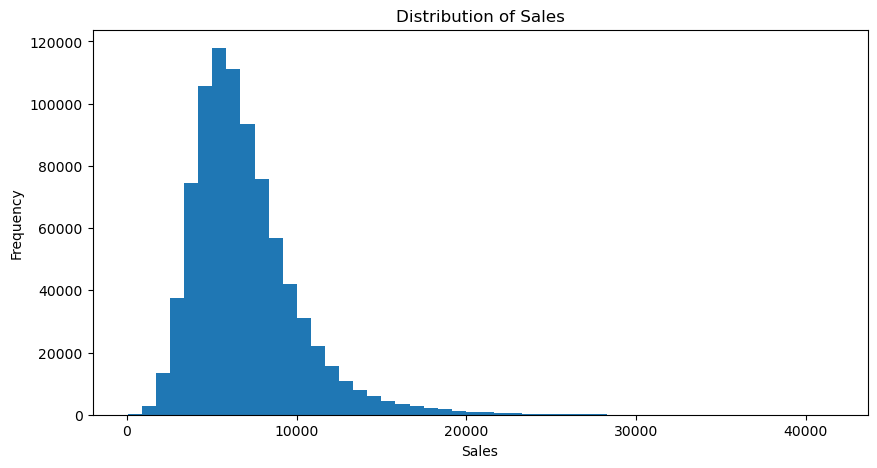

In [15]:
plt.figure(figsize=(10, 5))

plt.hist(train.loc[train["Sales"] > 0, "Sales"], bins=50)

plt.title("Distribution of Sales")
plt.xlabel("Sales")
plt.ylabel("Frequency")

plt.show()

## Daily Sales Trend Over Time

In [16]:
daily_sales = train.groupby("Date")["Sales"].sum()

daily_sales.head()

Date
2013-01-01      97235
2013-01-02    6949829
2013-01-03    6347820
2013-01-04    6638954
2013-01-05    5951593
Name: Sales, dtype: int64

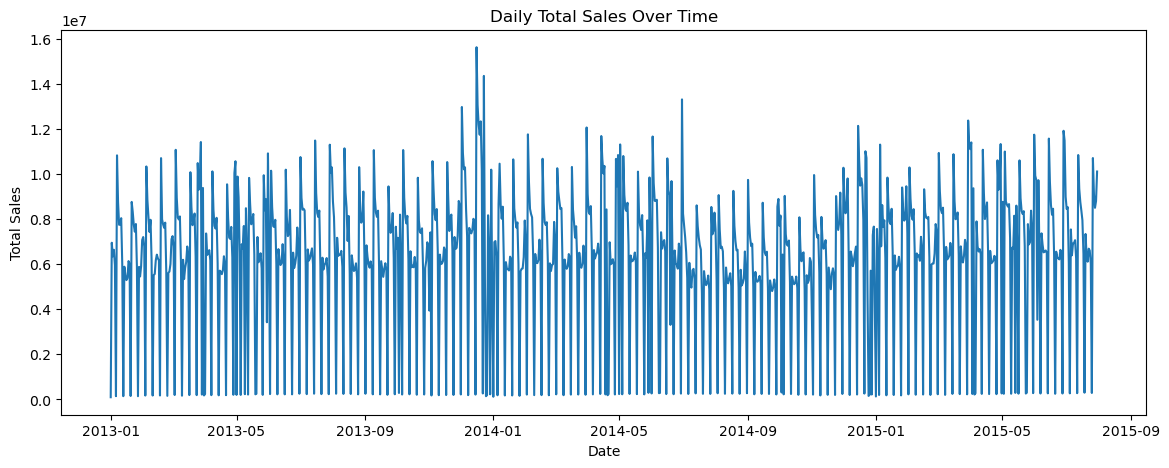

In [17]:
plt.figure(figsize=(14, 5))

plt.plot(daily_sales)

plt.title("Daily Total Sales Over Time")
plt.xlabel("Date")
plt.ylabel("Total Sales")

plt.show()

## Monthly Sales Trend

In [18]:
monthly_sales = train.groupby(
    train["Date"].dt.to_period("M")
)["Sales"].sum()

monthly_sales.head()

Date
2013-01    180132207
2013-02    171534275
2013-03    201180369
2013-04    183431432
2013-05    185411063
Freq: M, Name: Sales, dtype: int64

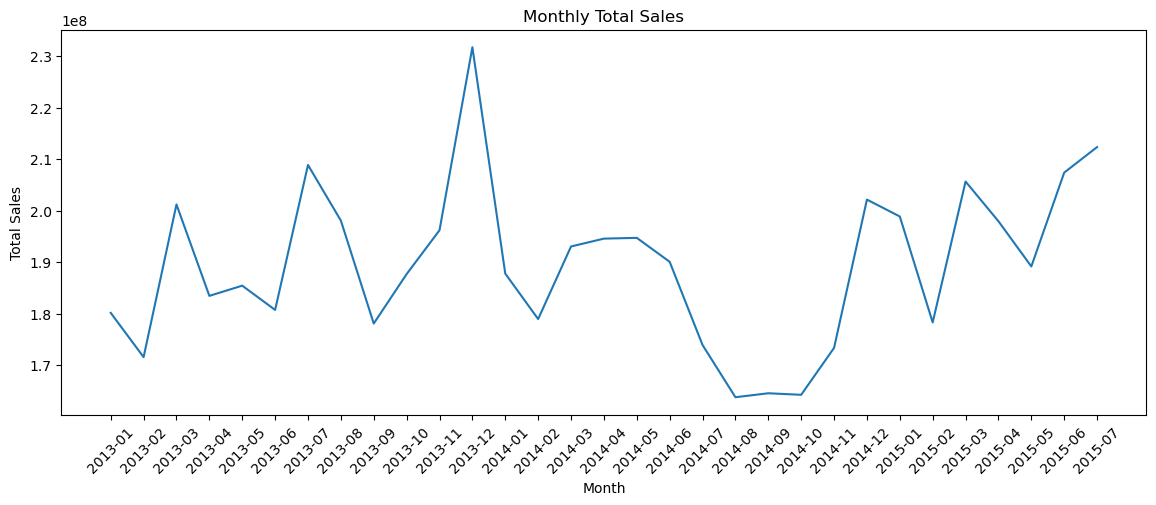

In [19]:
plt.figure(figsize=(14, 5))

plt.plot(monthly_sales.index.astype(str), monthly_sales.values)

plt.title("Monthly Total Sales")
plt.xlabel("Month")
plt.ylabel("Total Sales")

plt.xticks(rotation=45)
plt.show()

## Monthly Average Sales

In [20]:
monthly_avg_sales = train.groupby(
    train["Date"].dt.to_period("M")
)["Sales"].mean()

monthly_avg_sales.head()

Date
2013-01    5211.555578
2013-02    5494.371397
2013-03    5820.349168
2013-04    5483.749836
2013-05    5364.127383
Freq: M, Name: Sales, dtype: float64

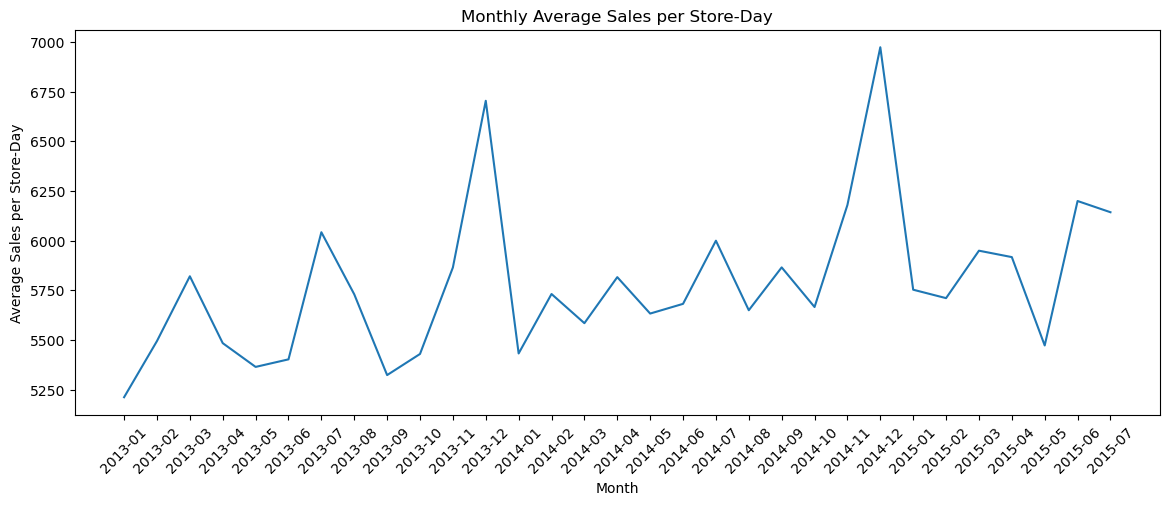

In [21]:
plt.figure(figsize=(14, 5))

plt.plot(
    monthly_avg_sales.index.astype(str),
    monthly_avg_sales.values
)

plt.title("Monthly Average Sales per Store-Day")
plt.xlabel("Month")
plt.ylabel("Average Sales per Store-Day")

plt.xticks(rotation=45)
plt.show()

## Promotion Analysis In Python

In [22]:
promo_summary = train.groupby("Promo").agg(
    Total_Sales=("Sales", "sum"),
    Total_Customers=("Customers", "sum"),
    Average_Sales=("Sales", "mean"),
    Average_Customers=("Customers", "mean")
)

promo_summary

,Total_Sales,Total_Customers,Average_Sales,Average_Customers
Promo,,,,
0,2771974337,325777807,4406.050805,517.823542
1,3101206286,318263948,7991.152046,820.098815


In [23]:
promo_summary["Sales_per_Customer"] = (
    promo_summary["Total_Sales"] /
    promo_summary["Total_Customers"]
)

promo_summary

,Total_Sales,Total_Customers,Average_Sales,Average_Customers,Sales_per_Customer
Promo,,,,,
0,2771974337,325777807,4406.050805,517.823542,8.508788
1,3101206286,318263948,7991.152046,820.098815,9.744133


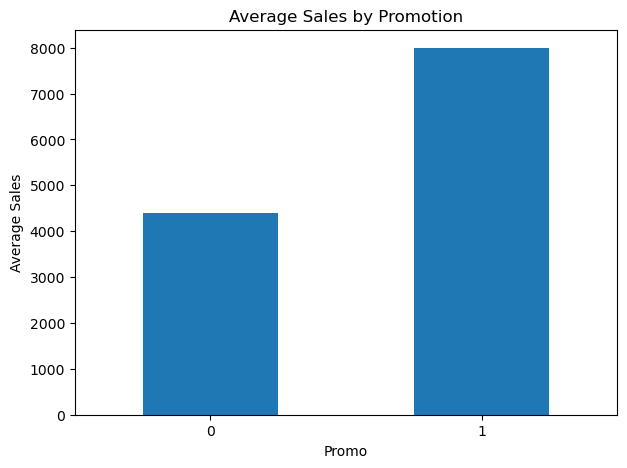

In [24]:
promo_summary["Average_Sales"].plot(
    kind="bar",
    figsize=(7, 5)
)

plt.title("Average Sales by Promotion")
plt.xlabel("Promo")
plt.ylabel("Average Sales")

plt.xticks(rotation=0)
plt.show()

## Customer Traffic vs Sales

In [25]:
train[["Sales", "Customers"]].corr()

,Sales,Customers
Sales,1.000000,0.894711
Customers,0.894711,1.000000


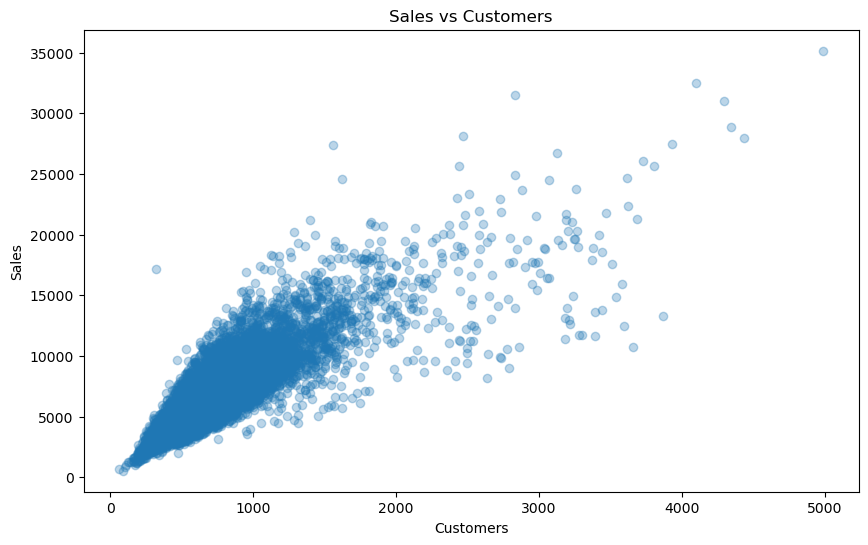

In [26]:
sample = train[train["Sales"] > 0].sample(
    10000,
    random_state=42
)

plt.figure(figsize=(10, 6))

plt.scatter(
    sample["Customers"],
    sample["Sales"],
    alpha=0.3
)

plt.title("Sales vs Customers")
plt.xlabel("Customers")
plt.ylabel("Sales")

plt.show()

## StoreType Analysis in Python

In [27]:
store_path = "../../1. Raw Data/store.csv"

store = pd.read_csv(store_path)

print("Store data loaded successfully!")
print("Rows:", store.shape[0])
print("Columns:", store.shape[1])

Store data loaded successfully!
Rows: 1115
Columns: 10


In [28]:
store[["Store", "StoreType"]].head()

,Store,StoreType
0,1,c
1,2,a
2,3,a
3,4,c
4,5,a


In [29]:
train_store = train.merge(
    store[["Store", "StoreType"]],
    on="Store",
    how="left"
)

train_store.head()

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType
0,1,5,2015-07-31,5263,555,1,1,0,1,c
1,2,5,2015-07-31,6064,625,1,1,0,1,a
2,3,5,2015-07-31,8314,821,1,1,0,1,a
3,4,5,2015-07-31,13995,1498,1,1,0,1,c
4,5,5,2015-07-31,4822,559,1,1,0,1,a


In [30]:
storetype_summary = train_store.groupby("StoreType").agg(
    Total_Sales=("Sales", "sum"),
    Total_Customers=("Customers", "sum"),
    Average_Sales=("Sales", "mean")
)

storetype_summary

,Total_Sales,Total_Customers,Average_Sales
StoreType,,,
a,3165334859,363541434,5738.179710
b,159231395,31465621,10058.837334
c,783221426,92129705,5723.629246
d,1765392943,156904995,5641.819243


## Analyze Sales by Day of Week

In [31]:
day_summary = train.groupby("DayOfWeek").agg(
    Total_Sales=("Sales", "sum"),
    Total_Customers=("Customers", "sum"),
    Average_Sales=("Sales", "mean"),
    Average_Customers=("Customers", "mean")
)

day_summary

,Total_Sales,Total_Customers,Average_Sales,Average_Customers
DayOfWeek,,,,
1,1130203012,117675012,7809.044510,813.065791
2,1020411930,110848063,7005.244467,760.984615
3,954962863,105117642,6555.884138,721.639666
4,911177709,101732938,6247.575913,697.541486
5,980555941,108384820,6723.274305,743.150742
6,846317735,95103854,5847.562599,657.112237
7,29551433,5179426,204.183189,35.786817


In [32]:
day_names = {
    1: "Monday",
    2: "Tuesday",
    3: "Wednesday",
    4: "Thursday",
    5: "Friday",
    6: "Saturday",
    7: "Sunday"
}

day_summary.index = day_summary.index.map(day_names)

day_summary

,Total_Sales,Total_Customers,Average_Sales,Average_Customers
DayOfWeek,,,,
Monday,1130203012,117675012,7809.044510,813.065791
Tuesday,1020411930,110848063,7005.244467,760.984615
Wednesday,954962863,105117642,6555.884138,721.639666
Thursday,911177709,101732938,6247.575913,697.541486
Friday,980555941,108384820,6723.274305,743.150742
Saturday,846317735,95103854,5847.562599,657.112237
Sunday,29551433,5179426,204.183189,35.786817


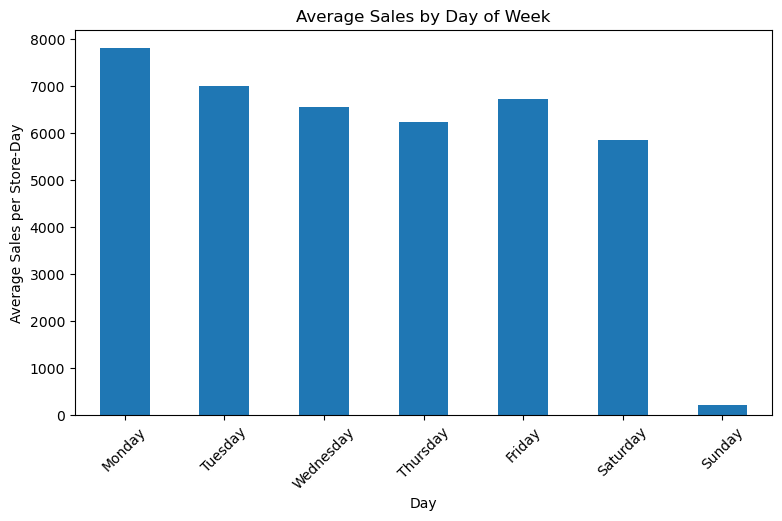

In [33]:
day_summary["Average_Sales"].plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Average Sales by Day of Week")
plt.xlabel("Day")
plt.ylabel("Average Sales per Store-Day")

plt.xticks(rotation=45)
plt.show()

In [34]:
train["Year"] = train["Date"].dt.year

In [35]:
train["Month"] = train["Date"].dt.month

In [36]:
train["Day"] = train["Date"].dt.day

In [37]:
train["WeekOfYear"] = train["Date"].dt.isocalendar().week.astype(int)

In [38]:
train[
    ["Date", "Year", "Month", "Day", "WeekOfYear"]
].head()

,Date,Year,Month,Day,WeekOfYear
0,2015-07-31,2015,7,31,31
1,2015-07-31,2015,7,31,31
2,2015-07-31,2015,7,31,31
3,2015-07-31,2015,7,31,31
4,2015-07-31,2015,7,31,31


## Lagged Sales

In [39]:
train = train.sort_values(
    ["Store", "Date"]
).reset_index(drop=True)

In [40]:
train["Sales_Lag_1"] = (
    train.groupby("Store")["Sales"].shift(1)
)

In [41]:
train[
    ["Store", "Date", "Sales", "Sales_Lag_1"]
].head(10)

,Store,Date,Sales,Sales_Lag_1
0,1,2013-01-01,0,NaN
1,1,2013-01-02,5530,0.0
2,1,2013-01-03,4327,5530.0
3,1,2013-01-04,4486,4327.0
4,1,2013-01-05,4997,4486.0
5,1,2013-01-06,0,4997.0
6,1,2013-01-07,7176,0.0
7,1,2013-01-08,5580,7176.0
8,1,2013-01-09,5471,5580.0
9,1,2013-01-10,4892,5471.0


In [42]:
train["Sales_Lag_7"] = (
    train.groupby("Store")["Sales"].shift(7)
)

In [43]:
train["Sales_Lag_14"] = (
    train.groupby("Store")["Sales"].shift(14)
)

In [44]:
train[
    [
        "Store",
        "Date",
        "Sales",
        "Sales_Lag_1",
        "Sales_Lag_7",
        "Sales_Lag_14"
    ]
].head(20)

,Store,Date,Sales,Sales_Lag_1,Sales_Lag_7,Sales_Lag_14
0,1,2013-01-01,0,NaN,NaN,NaN
1,1,2013-01-02,5530,0.0,NaN,NaN
2,1,2013-01-03,4327,5530.0,NaN,NaN
3,1,2013-01-04,4486,4327.0,NaN,NaN
4,1,2013-01-05,4997,4486.0,NaN,NaN
5,1,2013-01-06,0,4997.0,NaN,NaN
6,1,2013-01-07,7176,0.0,NaN,NaN
7,1,2013-01-08,5580,7176.0,0.0,NaN
8,1,2013-01-09,5471,5580.0,5530.0,NaN
9,1,2013-01-10,4892,5471.0,4327.0,NaN


## Rolling Sales Features

In [45]:
train["Sales_Rolling_7"] = (
    train.groupby("Store")["Sales"]
    .transform(lambda x: x.shift(1).rolling(7).mean())
)

In [46]:
train["Sales_Rolling_14"] = (
    train.groupby("Store")["Sales"]
    .transform(lambda x: x.shift(1).rolling(14).mean())
)

In [47]:
train[
    [
        "Store",
        "Date",
        "Sales",
        "Sales_Lag_1",
        "Sales_Lag_7",
        "Sales_Lag_14",
        "Sales_Rolling_7",
        "Sales_Rolling_14"
    ]
].head(25)

,Store,Date,Sales,Sales_Lag_1,Sales_Lag_7,Sales_Lag_14,Sales_Rolling_7,Sales_Rolling_14
0,1,2013-01-01,0,NaN,NaN,NaN,NaN,NaN
1,1,2013-01-02,5530,0.0,NaN,NaN,NaN,NaN
2,1,2013-01-03,4327,5530.0,NaN,NaN,NaN,NaN
3,1,2013-01-04,4486,4327.0,NaN,NaN,NaN,NaN
4,1,2013-01-05,4997,4486.0,NaN,NaN,NaN,NaN
5,1,2013-01-06,0,4997.0,NaN,NaN,NaN,NaN
6,1,2013-01-07,7176,0.0,NaN,NaN,NaN,NaN
7,1,2013-01-08,5580,7176.0,0.0,NaN,3788.000000,NaN
8,1,2013-01-09,5471,5580.0,5530.0,NaN,4585.142857,NaN
9,1,2013-01-10,4892,5471.0,4327.0,NaN,4576.714286,NaN


## Add Promotion, Holiday & Store Features

In [48]:
train = train.merge(
    store[["Store", "StoreType", "Assortment", "CompetitionDistance"]],
    on="Store",
    how="left"
)

In [49]:
train[
    [
        "Store",
        "StoreType",
        "Assortment",
        "CompetitionDistance"
    ]
].head()

,Store,StoreType,Assortment,CompetitionDistance
0,1,c,a,1270.0
1,1,c,a,1270.0
2,1,c,a,1270.0
3,1,c,a,1270.0
4,1,c,a,1270.0


In [50]:
train[
    [
        "StoreType",
        "Assortment",
        "CompetitionDistance"
    ]
].isnull().sum()

StoreType                 0
Assortment                0
CompetitionDistance    2642
dtype: int64

## Check the Feature Set

In [51]:
train.columns.tolist()

['Store',
 'DayOfWeek',
 'Date',
 'Sales',
 'Customers',
 'Open',
 'Promo',
 'StateHoliday',
 'SchoolHoliday',
 'Year',
 'Month',
 'Day',
 'WeekOfYear',
 'Sales_Lag_1',
 'Sales_Lag_7',
 'Sales_Lag_14',
 'Sales_Rolling_7',
 'Sales_Rolling_14',
 'StoreType',
 'Assortment',
 'CompetitionDistance']

In [52]:
train.dtypes

Store                           int64
DayOfWeek                       int64
Date                   datetime64[ns]
Sales                           int64
Customers                       int64
Open                            int64
Promo                           int64
StateHoliday                   object
SchoolHoliday                   int64
Year                            int32
Month                           int32
Day                             int32
WeekOfYear                      int32
Sales_Lag_1                   float64
Sales_Lag_7                   float64
Sales_Lag_14                  float64
Sales_Rolling_7               float64
Sales_Rolling_14              float64
StoreType                      object
Assortment                     object
CompetitionDistance           float64
dtype: object

In [53]:
train.isnull().sum()

Store                      0
DayOfWeek                  0
Date                       0
Sales                      0
Customers                  0
Open                       0
Promo                      0
StateHoliday               0
SchoolHoliday              0
Year                       0
Month                      0
Day                        0
WeekOfYear                 0
Sales_Lag_1             1115
Sales_Lag_7             7805
Sales_Lag_14           15610
Sales_Rolling_7         7805
Sales_Rolling_14       15610
StoreType                  0
Assortment                 0
CompetitionDistance     2642
dtype: int64

In [54]:
train.dropna(
    subset=[
        "Sales_Lag_1",
        "Sales_Lag_7",
        "Sales_Lag_14",
        "Sales_Rolling_7",
        "Sales_Rolling_14"
    ]
).shape

(1001599, 21)

## Prepare the Modeling Data

In [55]:
model_data = train.dropna(
    subset=[
        "Sales_Lag_1",
        "Sales_Lag_7",
        "Sales_Lag_14",
        "Sales_Rolling_7",
        "Sales_Rolling_14"
    ]
).copy()

In [56]:
model_data.shape

(1001599, 21)

In [57]:
model_data.head()

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,Year,...,Day,WeekOfYear,Sales_Lag_1,Sales_Lag_7,Sales_Lag_14,Sales_Rolling_7,Sales_Rolling_14,StoreType,Assortment,CompetitionDistance
14,1,2,2013-01-15,3900,512,1,0,0,0,2013,...,15,3,4717.0,5580.0,0.0,4356.142857,4072.071429,c,a,1270.0
15,1,3,2013-01-16,4008,530,1,0,0,0,2013,...,16,3,3900.0,5471.0,5530.0,4116.142857,4350.642857,c,a,1270.0
16,1,4,2013-01-17,4044,503,1,0,0,0,2013,...,17,3,4008.0,4892.0,4327.0,3907.142857,4241.928571,c,a,1270.0
17,1,5,2013-01-18,4127,568,1,0,0,0,2013,...,18,3,4044.0,4881.0,4486.0,3786.000000,4221.714286,c,a,1270.0
18,1,6,2013-01-19,5182,688,1,0,0,0,2013,...,19,3,4127.0,4952.0,4997.0,3678.285714,4196.071429,c,a,1270.0


## Train/Test Split by Time

In [58]:
print("Start date:", model_data["Date"].min())
print("End date:", model_data["Date"].max())

Start date: 2013-01-15 00:00:00
End date: 2015-07-31 00:00:00


In [59]:
cutoff_date = pd.Timestamp("2015-06-01")

In [60]:
train_data = model_data[
    model_data["Date"] < cutoff_date
].copy()

In [61]:
test_data = model_data[
    model_data["Date"] >= cutoff_date
].copy()

In [62]:
print("Training data:")
print(train_data.shape)

print("\nTest data:")
print(test_data.shape)

print("\nTraining period:")
print(train_data["Date"].min(), "to", train_data["Date"].max())

print("\nTest period:")
print(test_data["Date"].min(), "to", test_data["Date"].max())

Training data:
(933584, 21)

Test data:
(68015, 21)

Training period:
2013-01-15 00:00:00 to 2015-05-31 00:00:00

Test period:
2015-06-01 00:00:00 to 2015-07-31 00:00:00


## Create X and y

In [63]:
features = [
    "Store",
    "DayOfWeek",
    "Open",
    "Promo",
    "StateHoliday",
    "SchoolHoliday",
    "Year",
    "Month",
    "Day",
    "WeekOfYear",
    "Customers",
    "Sales_Lag_1",
    "Sales_Lag_7",
    "Sales_Lag_14",
    "Sales_Rolling_7",
    "Sales_Rolling_14",
    "StoreType",
    "Assortment",
    "CompetitionDistance"
]

In [64]:
X_train = train_data[features]
y_train = train_data["Sales"]

In [65]:
X_test = test_data[features]
y_test = test_data["Sales"]

In [66]:
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (933584, 19)
y_train: (933584,)
X_test: (68015, 19)
y_test: (68015,)


## Train the First Model

In [67]:
from sklearn.ensemble import RandomForestRegressor

In [68]:
model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

## Encoding Categorical Features.

In [69]:
from sklearn.preprocessing import OneHotEncoder

In [70]:
categorical_features = [
    "StateHoliday",
    "StoreType",
    "Assortment"
]

encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

In [71]:
X_train_cat = X_train[categorical_features].astype(str)
X_test_cat = X_test[categorical_features].astype(str)

In [72]:
encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

In [73]:
X_train_encoded = encoder.fit_transform(X_train_cat)

X_test_encoded = encoder.transform(X_test_cat)

In [74]:
print("Encoded training shape:", X_train_encoded.shape)
print("Encoded test shape:", X_test_encoded.shape)

Encoded training shape: (933584, 11)
Encoded test shape: (68015, 11)


In [75]:
numerical_features = [
    "Store",
    "DayOfWeek",
    "Open",
    "Promo",
    "SchoolHoliday",
    "Year",
    "Month",
    "Day",
    "WeekOfYear",
    "Customers",
    "Sales_Lag_1",
    "Sales_Lag_7",
    "Sales_Lag_14",
    "Sales_Rolling_7",
    "Sales_Rolling_14",
    "CompetitionDistance"
]

In [76]:
X_train_num = X_train[numerical_features]
X_test_num = X_test[numerical_features]

In [77]:
print("Numerical training:", X_train_num.shape)
print("Numerical test:", X_test_num.shape)

Numerical training: (933584, 16)
Numerical test: (68015, 16)


## Combine the Features

In [78]:
import numpy as np

In [79]:
X_train_final = np.hstack([
    X_train_num.values,
    X_train_encoded
])

In [80]:
X_test_final = np.hstack([
    X_test_num.values,
    X_test_encoded
])

In [81]:
print("Final training data:", X_train_final.shape)
print("Final test data:", X_test_final.shape)

Final training data: (933584, 27)
Final test data: (68015, 27)


## Train the Random Forest model

In [83]:
model = RandomForestRegressor(
    n_estimators=20,
    max_depth=15,
    random_state=42,
    n_jobs=-1
)

In [85]:
model.fit(X_train_final, y_train)

RandomForestRegressor(max_depth=15, n_estimators=20, n_jobs=-1, random_state=42)

## Make Predictions

In [86]:
y_pred = model.predict(X_test_final)

In [87]:
y_pred[:10]

array([5972.11165465, 5230.44618597, 5193.35135823,    0.        ,
       6874.3365009 , 4264.77504215,    0.        , 3920.52884421,
       3935.41695624, 3891.36979365])

In [88]:
comparison = pd.DataFrame({
    "Actual Sales": y_test.values[:10],
    "Predicted Sales": y_pred[:10]
})

comparison

,Actual Sales,Predicted Sales
0,5774,5972.111655
1,5450,5230.446186
2,5809,5193.351358
3,0,0.000000
4,5384,6874.336501
5,4183,4264.775042
6,0,0.000000
7,4071,3920.528844
8,4102,3935.416956
9,3591,3891.369794


## Model Evaluation

In [89]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [90]:
mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))

r2 = r2_score(y_test, y_pred)

print("MAE :", mae)
print("RMSE:", rmse)
print("R²  :", r2)

MAE : 450.9981335624256
RMSE: 688.2961513132898
R²  : 0.9672143932728846


## Actual vs Predicted Visualization

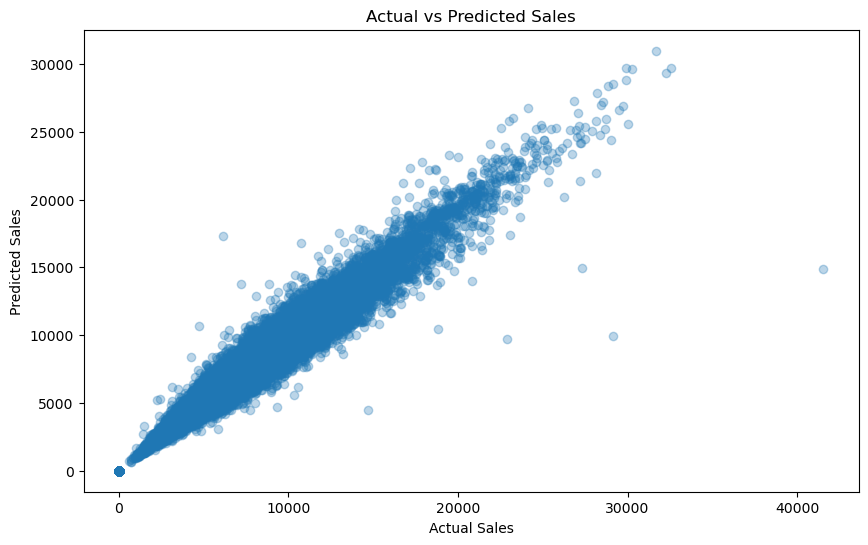

In [91]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.scatter(y_test, y_pred, alpha=0.3)

plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Actual vs Predicted Sales")

plt.show()

## Feature Importance

In [92]:
model.feature_importances_

array([1.30901180e-03, 4.79206805e-03, 0.00000000e+00, 1.11581398e-02,
       8.16128863e-05, 1.65245339e-04, 4.84206834e-04, 4.35132637e-03,
       2.78909663e-03, 7.96012936e-01, 4.50671970e-02, 2.88447623e-03,
       1.05837813e-01, 4.77047009e-03, 9.07302539e-03, 4.16077116e-03,
       9.23674899e-05, 1.80960881e-05, 2.94892007e-06, 4.92608323e-07,
       1.15210566e-04, 4.20755843e-04, 1.45180271e-04, 5.12006637e-03,
       1.21148814e-04, 9.05862614e-04, 1.20473921e-04])

In [93]:
feature_importance = model.feature_importances_

print(feature_importance)

[1.30901180e-03 4.79206805e-03 0.00000000e+00 1.11581398e-02
 8.16128863e-05 1.65245339e-04 4.84206834e-04 4.35132637e-03
 2.78909663e-03 7.96012936e-01 4.50671970e-02 2.88447623e-03
 1.05837813e-01 4.77047009e-03 9.07302539e-03 4.16077116e-03
 9.23674899e-05 1.80960881e-05 2.94892007e-06 4.92608323e-07
 1.15210566e-04 4.20755843e-04 1.45180271e-04 5.12006637e-03
 1.21148814e-04 9.05862614e-04 1.20473921e-04]


In [94]:
encoded_feature_names = encoder.get_feature_names_out(categorical_features)

In [95]:
all_feature_names = numerical_features + list(encoded_feature_names)

In [96]:
importance_df = pd.DataFrame({
    "Feature": all_feature_names,
    "Importance": feature_importance
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

importance_df.head(15)

,Feature,Importance
9,Customers,0.796013
12,Sales_Lag_14,0.105838
10,Sales_Lag_1,0.045067
3,Promo,0.011158
14,Sales_Rolling_14,0.009073
23,StoreType_d,0.005120
1,DayOfWeek,0.004792
13,Sales_Rolling_7,0.004770
7,Day,0.004351
15,CompetitionDistance,0.004161


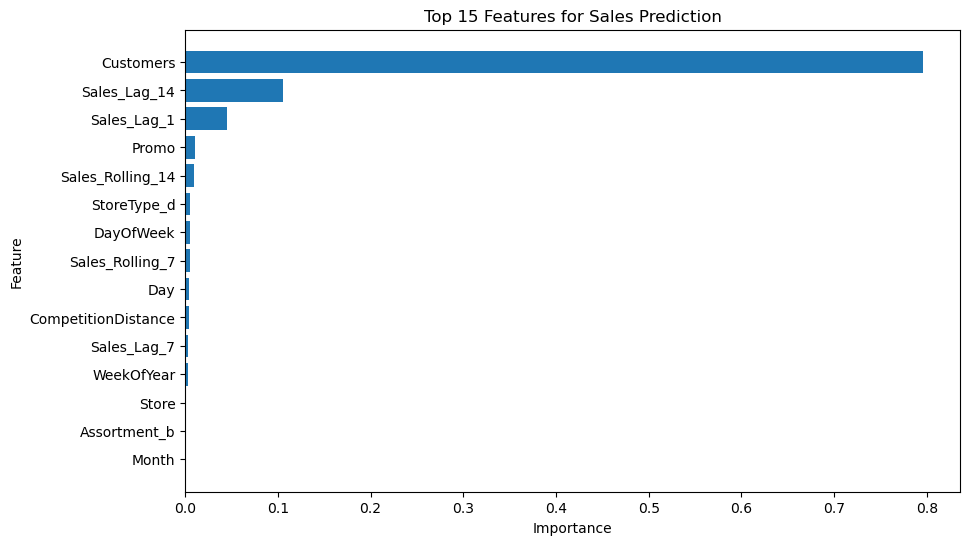

In [97]:
top_features = importance_df.head(15)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 15 Features for Sales Prediction")

plt.gca().invert_yaxis()

plt.show()

## Create the Final Forecast Output

In [98]:
forecast_results = pd.DataFrame({
    "Actual Sales": y_test.values,
    "Predicted Sales": y_pred
})

forecast_results["Error"] = (
    forecast_results["Actual Sales"]
    - forecast_results["Predicted Sales"]
)

forecast_results.head(10)

,Actual Sales,Predicted Sales,Error
0,5774,5972.111655,-198.111655
1,5450,5230.446186,219.553814
2,5809,5193.351358,615.648642
3,0,0.000000,0.000000
4,5384,6874.336501,-1490.336501
5,4183,4264.775042,-81.775042
6,0,0.000000,0.000000
7,4071,3920.528844,150.471156
8,4102,3935.416956,166.583044
9,3591,3891.369794,-300.369794


In [100]:
print("X_test columns:")
print(X_test.columns.tolist())

X_test columns:
['Store', 'DayOfWeek', 'Open', 'Promo', 'StateHoliday', 'SchoolHoliday', 'Year', 'Month', 'Day', 'WeekOfYear', 'Customers', 'Sales_Lag_1', 'Sales_Lag_7', 'Sales_Lag_14', 'Sales_Rolling_7', 'Sales_Rolling_14', 'StoreType', 'Assortment', 'CompetitionDistance']


In [101]:
print("Available dataframes:")
print(train.columns.tolist())

Available dataframes:
['Store', 'DayOfWeek', 'Date', 'Sales', 'Customers', 'Open', 'Promo', 'StateHoliday', 'SchoolHoliday', 'Year', 'Month', 'Day', 'WeekOfYear', 'Sales_Lag_1', 'Sales_Lag_7', 'Sales_Lag_14', 'Sales_Rolling_7', 'Sales_Rolling_14', 'StoreType', 'Assortment', 'CompetitionDistance']


In [102]:
forecast_results.to_csv(
    "sales_forecast_results.csv",
    index=False
)

In [103]:
import os

print(os.path.exists("sales_forecast_results.csv"))

True


In [104]:
forecast_results.shape

(68015, 4)

In [105]:
forecast_results.head()

,Actual Sales,Predicted Sales,Error,Store
0,5774,5972.111655,-198.111655,1
1,5450,5230.446186,219.553814,1
2,5809,5193.351358,615.648642,1
3,0,0.000000,0.000000,1
4,5384,6874.336501,-1490.336501,1
